In [23]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as ses
import sklearn as sns

In [7]:
card = pd.read_csv("C:/Users/GUPTA/Downloads/creditcard.csv")

In [10]:
card.tail()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
284802,172786.0,-11.881118,10.071785,-9.834783,-2.066656,-5.364473,-2.606837,-4.918215,7.305334,1.914428,...,0.213454,0.111864,1.014480,-0.509348,1.436807,0.250034,0.943651,0.823731,0.77,0
284803,172787.0,-0.732789,-0.055080,2.035030,-0.738589,0.868229,1.058415,0.024330,0.294869,0.584800,...,0.214205,0.924384,0.012463,-1.016226,-0.606624,-0.395255,0.068472,-0.053527,24.79,0
284804,172788.0,1.919565,-0.301254,-3.249640,-0.557828,2.630515,3.031260,-0.296827,0.708417,0.432454,...,0.232045,0.578229,-0.037501,0.640134,0.265745,-0.087371,0.004455,-0.026561,67.88,0
284805,172788.0,-0.240440,0.530483,0.702510,0.689799,-0.377961,0.623708,-0.686180,0.679145,0.392087,...,0.265245,0.800049,-0.163298,0.123205,-0.569159,0.546668,0.108821,0.104533,10.00,0
284806,172792.0,-0.533413,-0.189733,0.703337,-0.506271,-0.012546,-0.649617,1.577006,-0.414650,0.486180,...,0.261057,0.643078,0.376777,0.008797,-0.473649,-0.818267,-0.002415,0.013649,217.00,0


In [9]:
card.columns

Index(['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10',
       'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20',
       'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount',
       'Class'],
      dtype='str')

In [11]:
card["Class"].unique()

array([0, 1])

In [12]:
card.info()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

In [16]:
# Total Transaction 
total = len(card)
print("Total Transaction:", total)
# Fraud transactions
fraud = card["Class"].sum()
print("Fraud Transactions: ", fraud)
# Fraud percentage
fraud_percentage = (fraud / total) * 100
print("Total fraud percentage:", fraud_percentage)



Total Transaction: 284807
Fraud Transactions:  492
Total fraud percentage: 0.1727485630620034


## 2. fraud vs. non-fraud

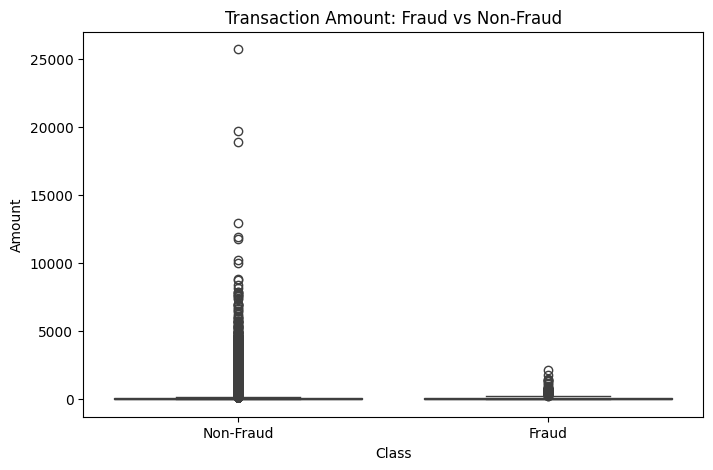

In [28]:
plt.figure(figsize=(8, 5))

ses.boxplot(
    data=card,
    x="Class",
    y="Amount"
)

plt.xticks([0, 1], ["Non-Fraud", "Fraud"])
plt.title("Transaction Amount: Fraud vs Non-Fraud")
plt.show()

## time-of-day analysis


In [29]:
card["Hour"] = (card["Time"] // 3600) %24

In [32]:
hourly_transaction = card.groupby(
    ["Hour", "Class"]
).size().reset_index(name="count")
print(hourly_transaction.head())

   Hour  Class  count
0   0.0      0   7689
1   0.0      1      6
2   1.0      0   4210
3   1.0      1     10
4   2.0      0   3271


In [41]:
print(hourly_transaction.columns)

Index(['Hour', 'Class', 'count'], dtype='str')


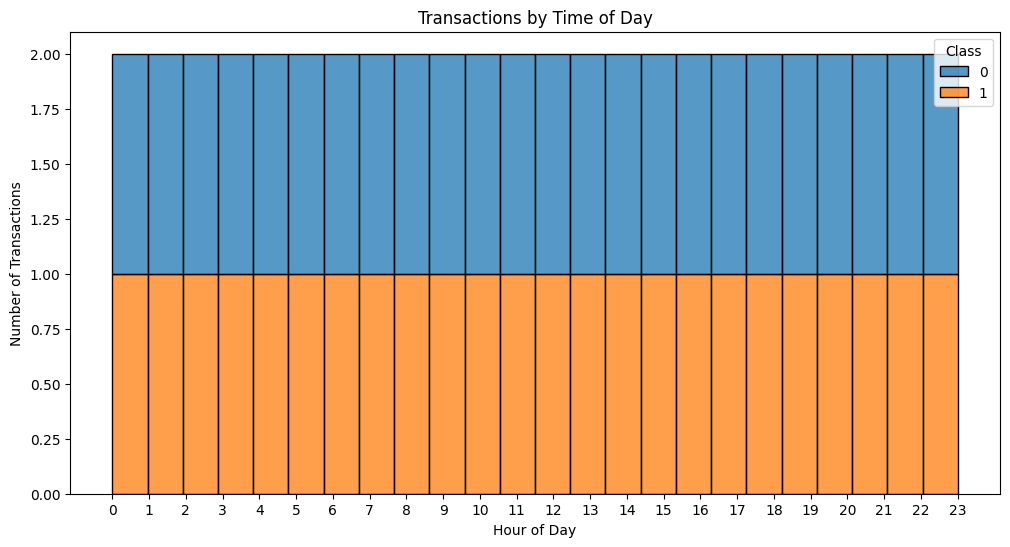

In [42]:
plt.figure(figsize=(12, 6))

ses.histplot(
    data=hourly_transaction,
    x="Hour",
    hue="Class",
    bins=24,
    multiple="stack"
)

plt.title("Transactions by Time of Day")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Transactions")
plt.xticks(range(24))
plt.show()

## misleading metric

### Why Accuracy Is Misleading for Imbalanced Fraud Datasets

Accuracy can be a misleading metric for fraud detection because the dataset is highly imbalanced. There are many more non-fraudulent transactions than fraudulent transactions.

For example, if 99.8% of transactions are non-fraudulent, a model that predicts every transaction as non-fraudulent could achieve about 99.8% accuracy while detecting **zero fraud transactions**.

Therefore, accuracy alone does not show how well the model detects fraud. For an imbalanced fraud dataset, we should also consider **Precision, Recall, F1-Score, Confusion Matrix, and ROC-AUC**.

**Recall is especially important because it measures how many actual fraudulent transactions are correctly identified by the model.**

In [46]:
X = card.drop("Class", axis=1)
y = card["Class"]

In [47]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [48]:
from imblearn.over_sampling import SMOTE

# Apply SMOTE only to training data
smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train,
    y_train
)

print("Before SMOTE:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(y_train_smote.value_counts())

Before SMOTE:
Class
0    227451
1       394
Name: count, dtype: int64

After SMOTE:
Class
0    227451
1    227451
Name: count, dtype: int64


In [50]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training set:")
print(y_train.value_counts())

print("\nTesting set:")
print(y_test.value_counts())

Training set:
Class
0    227451
1       394
Name: count, dtype: int64

Testing set:
Class
0    56864
1       98
Name: count, dtype: int64
